# Analisis Pengaruh Ukuran Dataset terhadap Waktu Pelatihan Model Machine Learning
## Menggunakan Regresi Linear Sederhana

---

**Mata Kuliah:** Machine Learning  
**Topik Praktikum:** Regresi Linear  

---

### Deskripsi Proyek

Notebook ini bertujuan untuk menganalisis hubungan antara **ukuran dataset pelatihan** (dalam MB) dan **waktu yang dibutuhkan** untuk melatih sebuah model Machine Learning (dalam menit) menggunakan algoritma **Regresi Linear Sederhana**.

**Variabel Penelitian:**
- **Variabel Independen (X):** `training_data_size_mb` — Ukuran dataset dalam satuan Megabyte (MB)
- **Variabel Dependen (y):** `training_time_minutes` — Waktu pelatihan dalam satuan menit

---
## Langkah 1 — Import Library

Pada tahap ini, kita mengimpor seluruh library Python yang diperlukan untuk analisis data dan pembuatan model Regresi Linear.

| Library | Fungsi |
|---|---|
| `pandas` | Membaca, memproses, dan memanipulasi data dalam bentuk tabel (DataFrame) |
| `numpy` | Melakukan komputasi numerik dan operasi matematika pada array |
| `matplotlib.pyplot` | Membuat visualisasi data dalam bentuk grafik dan plot |
| `seaborn` | Membuat visualisasi statistik yang lebih informatif dan estetis di atas Matplotlib |
| `sklearn.model_selection.train_test_split` | Membagi dataset menjadi data training dan data testing |
| `sklearn.linear_model.LinearRegression` | Membuat dan melatih model Regresi Linear |
| `sklearn.metrics` | Menghitung metrik evaluasi performa model seperti MAE, MSE, RMSE, dan R² |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn import metrics

from pathlib import Path

print("Seluruh library berhasil diimpor!")

Seluruh library berhasil diimpor!


---
## Langkah 2 — Memuat dan Memahami Dataset

Dataset dibaca langsung dari folder `data` menggunakan path relatif. Pendekatan ini memastikan notebook dapat dijalankan di komputer lain selama struktur folder tetap sama.

Pada tahap eksplorasi, kita akan:
1. Menampilkan beberapa baris pertama dan terakhir dataset
2. Memeriksa jumlah baris dan kolom
3. Melihat tipe data dan informasi umum dataset
4. Melihat statistik deskriptif

In [2]:
# Membaca dataset dari folder data menggunakan path relatif
dataset_path = Path("../data/training_data_vs_training_time_updated.csv")

df = pd.read_csv(dataset_path)

print(f"Dataset berhasil dimuat dari: {dataset_path}")
print(f"Jumlah baris dan kolom (awal): {df.shape}")

Dataset berhasil dimuat dari: ..\data\training_data_vs_training_time_updated.csv
Jumlah baris dan kolom (awal): (300, 3)


In [3]:
# Menampilkan 5 baris pertama dataset
print("=== Lima Baris Pertama Dataset ===")
df.head()

=== Lima Baris Pertama Dataset ===


,training_data_size_mb,training_time_minutes,Unnamed: 2
0,1935.25,170.73,NaN
1,4758.50,382.65,NaN
2,3686.77,352.82,NaN
3,3033.43,270.35,NaN
4,864.49,43.66,NaN


In [4]:
# Menampilkan 5 baris terakhir dataset
print("=== Lima Baris Terakhir Dataset ===")
df.tail()

=== Lima Baris Terakhir Dataset ===


,training_data_size_mb,training_time_minutes,Unnamed: 2
295,2658.99,228.68,NaN
296,3872.97,330.03,NaN
297,1157.52,89.52,NaN
298,3152.16,279.94,NaN
299,518.20,23.23,NaN


In [5]:
# Menampilkan jumlah baris dan kolom
print(f"Jumlah baris : {df.shape[0]}")
print(f"Jumlah kolom : {df.shape[1]}")

Jumlah baris : 300
Jumlah kolom : 3


In [6]:
# Menampilkan informasi umum dataset
print("=== Informasi Dataset ===")
df.info()

=== Informasi Dataset ===
<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 3 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   training_data_size_mb  300 non-null    float64
 1   training_time_minutes  300 non-null    float64
 2   Unnamed: 2             0 non-null      float64
dtypes: float64(3)
memory usage: 7.2 KB


In [7]:
# Menampilkan statistik deskriptif
print("=== Statistik Deskriptif ===")
df.describe()

=== Statistik Deskriptif ===


,training_data_size_mb,training_time_minutes,Unnamed: 2
count,300.000000,300.000000,0.0
mean,2526.502733,216.836133,NaN
std,1442.268904,118.580471,NaN
min,124.800000,-1.000000,NaN
25%,1271.492500,113.992500,NaN
50%,2607.420000,221.825000,NaN
75%,3808.612500,317.055000,NaN
max,4951.260000,434.800000,NaN


In [8]:
# Menampilkan nama-nama kolom
print("=== Nama Kolom ===")
print(df.columns.tolist())

=== Nama Kolom ===
['training_data_size_mb', 'training_time_minutes', 'Unnamed: 2']


### Ringkasan Eksplorasi Dataset

Dari hasil eksplorasi di atas, dapat diketahui:
- Dataset memuat data ukuran dataset pelatihan (MB) dan waktu pelatihannya (menit)
- Terdapat kemungkinan kolom tambahan yang tidak diperlukan (misalnya kolom kosong akibat trailing comma pada CSV)
- Perlu dilakukan pemeriksaan terhadap nilai yang tidak valid, seperti waktu training negatif
- Proses **preprocessing** diperlukan sebelum data dapat digunakan untuk melatih model

---
## Langkah 3 — Preprocessing Data

Sebelum melatih model, kita perlu membersihkan dataset terlebih dahulu. Tahapan preprocessing meliputi:

- **A.** Menghapus kolom yang tidak diperlukan
- **B.** Memeriksa dan menangani missing values
- **C.** Memeriksa data duplikat
- **D.** Memeriksa dan menghapus nilai tidak valid
- **E.** Memastikan tipe data numerik
- **F.** Menampilkan ringkasan hasil preprocessing

In [9]:
# Menyimpan jumlah data sebelum preprocessing
jumlah_awal = df.shape[0]
print(f"Jumlah data sebelum preprocessing: {jumlah_awal} baris")

Jumlah data sebelum preprocessing: 300 baris


In [10]:
# ========================
# A. Menghapus Kolom yang Tidak Diperlukan
# ========================
print("=== A. Pemeriksaan Kolom Tidak Diperlukan ===")
print(f"Kolom sebelum pembersihan: {df.columns.tolist()}")

# Hapus kolom 'Unnamed' jika ada (muncul akibat trailing comma pada CSV)
kolom_unnamed = [col for col in df.columns if 'Unnamed' in str(col)]

if kolom_unnamed:
    df.drop(columns=kolom_unnamed, inplace=True)
    print(f"Kolom yang dihapus: {kolom_unnamed}")
else:
    print("Tidak ada kolom 'Unnamed' yang perlu dihapus.")

print(f"Kolom setelah pembersihan: {df.columns.tolist()}")

=== A. Pemeriksaan Kolom Tidak Diperlukan ===
Kolom sebelum pembersihan: ['training_data_size_mb', 'training_time_minutes', 'Unnamed: 2']
Kolom yang dihapus: ['Unnamed: 2']
Kolom setelah pembersihan: ['training_data_size_mb', 'training_time_minutes']


In [11]:
# ========================
# B. Memeriksa Missing Values
# ========================
print("=== B. Pemeriksaan Missing Values ===")
print("\nJumlah missing values sebelum pembersihan:")
print(df.isnull().sum())

# Hapus baris yang mengandung missing values pada kolom utama
df.dropna(subset=['training_data_size_mb', 'training_time_minutes'], inplace=True)

print("\nJumlah missing values setelah pembersihan:")
print(df.isnull().sum())

=== B. Pemeriksaan Missing Values ===

Jumlah missing values sebelum pembersihan:
training_data_size_mb    0
training_time_minutes    0
dtype: int64

Jumlah missing values setelah pembersihan:
training_data_size_mb    0
training_time_minutes    0
dtype: int64


In [12]:
# ========================
# C. Memeriksa Data Duplikat
# ========================
print("=== C. Pemeriksaan Data Duplikat ===")
jumlah_duplikat = df.duplicated().sum()
print(f"Jumlah baris duplikat yang ditemukan: {jumlah_duplikat}")

if jumlah_duplikat > 0:
    print("\nContoh baris duplikat:")
    print(df[df.duplicated(keep=False)].sort_values(by='training_data_size_mb').head(10))
    print("\nCatatan: Duplikat tidak dihapus otomatis karena kemungkinan merupakan pengamatan yang valid.")
else:
    print("Tidak ditemukan baris duplikat dalam dataset.")

=== C. Pemeriksaan Data Duplikat ===
Jumlah baris duplikat yang ditemukan: 0
Tidak ditemukan baris duplikat dalam dataset.


In [13]:
# ========================
# D. Memeriksa Nilai Tidak Valid
# ========================
print("=== D. Pemeriksaan Nilai Tidak Valid ===")

# Periksa nilai negatif atau nol pada training_time_minutes
waktu_tidak_valid = df[df['training_time_minutes'] <= 0]
print(f"Baris dengan waktu training <= 0 menit: {len(waktu_tidak_valid)} baris")
if len(waktu_tidak_valid) > 0:
    print(waktu_tidak_valid)

# Periksa nilai negatif atau nol pada training_data_size_mb
ukuran_tidak_valid = df[df['training_data_size_mb'] <= 0]
print(f"\nBaris dengan ukuran dataset <= 0 MB: {len(ukuran_tidak_valid)} baris")
if len(ukuran_tidak_valid) > 0:
    print(ukuran_tidak_valid)

# Hapus baris dengan nilai tidak valid
df = df[df['training_time_minutes'] > 0]
df = df[df['training_data_size_mb'] > 0]

print("\nBaris dengan nilai tidak valid telah dihapus.")

=== D. Pemeriksaan Nilai Tidak Valid ===
Baris dengan waktu training <= 0 menit: 1 baris
     training_data_size_mb  training_time_minutes
205                 145.07                   -1.0

Baris dengan ukuran dataset <= 0 MB: 0 baris

Baris dengan nilai tidak valid telah dihapus.


In [14]:
# ========================
# E. Memastikan Tipe Data Numerik
# ========================
print("=== E. Pemeriksaan Tipe Data ===")
print("Tipe data sebelum konversi:")
print(df[['training_data_size_mb', 'training_time_minutes']].dtypes)

# Konversi ke numerik dan tangani nilai yang tidak bisa dikonversi
df['training_data_size_mb'] = pd.to_numeric(df['training_data_size_mb'], errors='coerce')
df['training_time_minutes'] = pd.to_numeric(df['training_time_minutes'], errors='coerce')

# Hapus baris yang menjadi NaN setelah konversi
df.dropna(subset=['training_data_size_mb', 'training_time_minutes'], inplace=True)

# Reset index setelah semua pembersihan
df.reset_index(drop=True, inplace=True)

print("\nTipe data setelah konversi:")
print(df[['training_data_size_mb', 'training_time_minutes']].dtypes)

=== E. Pemeriksaan Tipe Data ===
Tipe data sebelum konversi:
training_data_size_mb    float64
training_time_minutes    float64
dtype: object

Tipe data setelah konversi:
training_data_size_mb    float64
training_time_minutes    float64
dtype: object


In [15]:
# ========================
# F. Ringkasan Hasil Preprocessing
# ========================
print("=== F. Ringkasan Hasil Preprocessing ===")
jumlah_akhir = df.shape[0]
jumlah_dihapus = jumlah_awal - jumlah_akhir

print(f"Jumlah data sebelum preprocessing : {jumlah_awal} baris")
print(f"Jumlah data setelah preprocessing : {jumlah_akhir} baris")
print(f"Jumlah data yang dihapus          : {jumlah_dihapus} baris")

print("\nLima baris pertama dataset bersih:")
print(df.head())

print("\nPemeriksaan missing values setelah preprocessing:")
print(df.isnull().sum())

=== F. Ringkasan Hasil Preprocessing ===
Jumlah data sebelum preprocessing : 300 baris
Jumlah data setelah preprocessing : 299 baris
Jumlah data yang dihapus          : 1 baris

Lima baris pertama dataset bersih:
   training_data_size_mb  training_time_minutes
0                1935.25                 170.73
1                4758.50                 382.65
2                3686.77                 352.82
3                3033.43                 270.35
4                 864.49                  43.66

Pemeriksaan missing values setelah preprocessing:
training_data_size_mb    0
training_time_minutes    0
dtype: int64


---
## Langkah 4 — Visualisasi Hubungan Antarvariabel

Pada tahap ini kita akan memvisualisasikan hubungan antara variabel `training_data_size_mb` dan `training_time_minutes` menggunakan **Pairplot** dari Seaborn.

Pairplot menampilkan:
- **Diagonal:** Distribusi (histogram/KDE) masing-masing variabel
- **Off-diagonal:** Scatter plot hubungan antara dua variabel

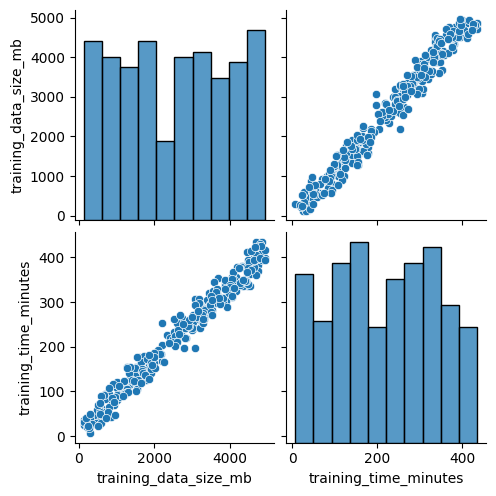

In [16]:
# Membuat pairplot untuk melihat hubungan dan distribusi kedua variabel
sns.pairplot(df[['training_data_size_mb', 'training_time_minutes']])
plt.show()

In [17]:
# Menghitung korelasi Pearson antara X dan y
korelasi = df['training_data_size_mb'].corr(df['training_time_minutes'])
print(f"Nilai Korelasi Pearson antara Ukuran Dataset dan Waktu Training: {korelasi:.4f}")

# Interpretasi nilai korelasi
if korelasi >= 0.8:
    interpretasi = "sangat kuat dan positif"
elif korelasi >= 0.6:
    interpretasi = "kuat dan positif"
elif korelasi >= 0.4:
    interpretasi = "sedang dan positif"
elif korelasi >= 0.2:
    interpretasi = "lemah dan positif"
elif korelasi > 0:
    interpretasi = "sangat lemah dan positif"
elif korelasi >= -0.2:
    interpretasi = "sangat lemah dan negatif"
elif korelasi >= -0.4:
    interpretasi = "lemah dan negatif"
elif korelasi >= -0.6:
    interpretasi = "sedang dan negatif"
elif korelasi >= -0.8:
    interpretasi = "kuat dan negatif"
else:
    interpretasi = "sangat kuat dan negatif"

print(f"\nInterpretasi: Hubungan antara ukuran dataset dan waktu training bersifat {interpretasi}.")
print("Artinya, semakin besar ukuran dataset, maka waktu training cenderung semakin lama.")

Nilai Korelasi Pearson antara Ukuran Dataset dan Waktu Training: 0.9860

Interpretasi: Hubungan antara ukuran dataset dan waktu training bersifat sangat kuat dan positif.
Artinya, semakin besar ukuran dataset, maka waktu training cenderung semakin lama.


### Interpretasi Visualisasi

Berdasarkan pairplot dan nilai korelasi Pearson di atas:
- **Scatter plot** (off-diagonal) menunjukkan pola hubungan antara ukuran dataset dan waktu training
- **Histogram/KDE** (diagonal) menunjukkan distribusi masing-masing variabel
- Nilai korelasi yang mendekati **+1** mengindikasikan hubungan linear yang kuat dan positif antara kedua variabel

---
## Langkah 5 — Persiapan Data untuk Model

Pada tahap ini, kita memisahkan dataset menjadi:
- **Fitur (X):** Variabel independen yaitu `training_data_size_mb`
- **Target (y):** Variabel dependen yaitu `training_time_minutes`

Kemudian dataset dibagi menjadi:
- **Data Training (70%):** Digunakan untuk melatih model
- **Data Testing (30%):** Digunakan untuk mengevaluasi performa model

In [18]:
# Memisahkan fitur (X) dan target (y)
X = df[['training_data_size_mb']]
y = df['training_time_minutes']

print("Fitur (X) - Ukuran Dataset:")
print(X.head())
print(f"\nBentuk X: {X.shape}")

print("\nTarget (y) - Waktu Training:")
print(y.head())
print(f"\nBentuk y: {y.shape}")

Fitur (X) - Ukuran Dataset:
   training_data_size_mb
0                1935.25
1                4758.50
2                3686.77
3                3033.43
4                 864.49

Bentuk X: (299, 1)

Target (y) - Waktu Training:
0    170.73
1    382.65
2    352.82
3    270.35
4     43.66
Name: training_time_minutes, dtype: float64

Bentuk y: (299,)


In [19]:
# Membagi data menjadi training dan testing
# test_size=0.3 → 30% untuk testing, 70% untuk training
# random_state=101 → agar hasil pembagian dapat direproduksi
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=101
)

print("=== Pembagian Data Training dan Testing ===")
print(f"Total data            : {len(X)} baris")
print(f"Data Training (70%)   : {len(X_train)} baris")
print(f"Data Testing  (30%)   : {len(X_test)} baris")
print("\nKeterangan:")
print("- 70% data digunakan untuk melatih model (training)")
print("- 30% data digunakan untuk menguji performa model (testing)")

=== Pembagian Data Training dan Testing ===
Total data            : 299 baris
Data Training (70%)   : 209 baris
Data Testing  (30%)   : 90 baris

Keterangan:
- 70% data digunakan untuk melatih model (training)
- 30% data digunakan untuk menguji performa model (testing)


---
## Langkah 6 — Pelatihan Model Regresi Linear

Model Regresi Linear Sederhana dibuat menggunakan `LinearRegression` dari `scikit-learn`. Model dilatih menggunakan data training yang telah dipisahkan sebelumnya.

Persamaan Regresi Linear:

$$Y = a + bX$$

Di mana:
- **Y** = Prediksi waktu training (menit)
- **X** = Ukuran dataset (MB)
- **a** = Intercept (nilai Y ketika X = 0)
- **b** = Koefisien regresi (kemiringan garis)

In [20]:
# Membuat dan melatih model Regresi Linear
model = LinearRegression()
model.fit(X_train, y_train)

print("Model Regresi Linear berhasil dilatih!")

Model Regresi Linear berhasil dilatih!


In [21]:
# Menampilkan parameter model
intercept = model.intercept_
koefisien = model.coef_[0]

print("=== Parameter Model Regresi Linear ===")
print(f"Intercept (a) : {intercept:.4f}")
print(f"Koefisien (b) : {koefisien:.4f}")
print("\n=== Persamaan Regresi Linear ===")
print(f"Y = {intercept:.4f} + {koefisien:.6f} * X")
print(f"\nAtau dalam bentuk lengkap:")
print(f"Waktu Training (menit) = {intercept:.4f} + {koefisien:.6f} * Ukuran Dataset (MB)")

print("\n=== Interpretasi Koefisien ===")
print(f"Setiap penambahan 1 MB ukuran dataset, waktu training diperkirakan")
print(f"bertambah sekitar {koefisien:.4f} menit ({koefisien*60:.2f} detik).")
print(f"\nIntercept sebesar {intercept:.4f} menunjukkan estimasi waktu dasar")
print(f"yang dibutuhkan bahkan ketika ukuran dataset sangat kecil.")

=== Parameter Model Regresi Linear ===
Intercept (a) : 11.4902
Koefisien (b) : 0.0814

=== Persamaan Regresi Linear ===
Y = 11.4902 + 0.081362 * X

Atau dalam bentuk lengkap:
Waktu Training (menit) = 11.4902 + 0.081362 * Ukuran Dataset (MB)

=== Interpretasi Koefisien ===
Setiap penambahan 1 MB ukuran dataset, waktu training diperkirakan
bertambah sekitar 0.0814 menit (4.88 detik).

Intercept sebesar 11.4902 menunjukkan estimasi waktu dasar
yang dibutuhkan bahkan ketika ukuran dataset sangat kecil.


---
## Langkah 7 — Melakukan Prediksi

Model yang telah dilatih digunakan untuk memprediksi waktu training pada data testing. Hasil prediksi kemudian dibandingkan dengan nilai aktual untuk mengetahui seberapa akurat model.

In [22]:
# Melakukan prediksi pada data testing
predictions = model.predict(X_test)

print("Prediksi berhasil dilakukan pada data testing!")
print(f"Jumlah prediksi: {len(predictions)}")

Prediksi berhasil dilakukan pada data testing!
Jumlah prediksi: 90


In [23]:
# Membuat tabel perbandingan nilai aktual dan prediksi
tabel_perbandingan = pd.DataFrame({
    'Ukuran Dataset (MB)'   : X_test['training_data_size_mb'].values,
    'Waktu Aktual (Menit)'  : y_test.values,
    'Waktu Prediksi (Menit)': np.round(predictions, 2),
    'Selisih Absolut (Menit)': np.round(np.abs(y_test.values - predictions), 2)
})

# Urutkan berdasarkan ukuran dataset untuk kemudahan pembacaan
tabel_perbandingan = tabel_perbandingan.sort_values(by='Ukuran Dataset (MB)').reset_index(drop=True)

print("=== Tabel Perbandingan Nilai Aktual vs Prediksi (10 Baris Pertama) ===")
print(tabel_perbandingan.head(10).to_string(index=True))

=== Tabel Perbandingan Nilai Aktual vs Prediksi (10 Baris Pertama) ===
   Ukuran Dataset (MB)  Waktu Aktual (Menit)  Waktu Prediksi (Menit)  Selisih Absolut (Menit)
0               134.07                 36.11                   22.40                    13.71
1               181.28                 30.44                   26.24                     4.20
2               224.55                 32.72                   29.76                     2.96
3               249.45                 21.70                   31.79                    10.09
4               276.12                 17.54                   33.96                    16.42
5               283.01                 49.05                   34.52                    14.53
6               418.75                 43.45                   45.56                     2.11
7               533.61                 63.31                   54.91                     8.40
8               576.16                 90.69                   58.37               

---
## Langkah 8 — Visualisasi Hasil Prediksi vs Nilai Aktual

Grafik di bawah menampilkan **scatter plot** perbandingan antara nilai waktu training aktual (sumbu X) dan nilai waktu training hasil prediksi model (sumbu Y).

**Cara membaca grafik:**
- **Garis merah** merupakan **garis ideal** (perfect prediction line), yaitu kondisi di mana prediksi sama persis dengan nilai aktual
- **Titik-titik biru** mewakili setiap data pada data testing
- Semakin dekat titik-titik ke garis merah, semakin akurat prediksi model
- Titik yang jauh dari garis merah menunjukkan error prediksi yang besar

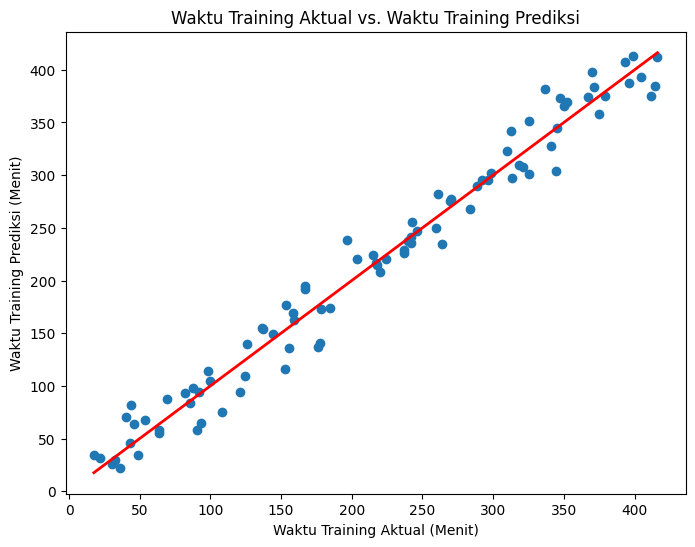

In [24]:
# Scatter plot: Nilai Aktual vs Nilai Prediksi
plt.figure(figsize=(8, 6))

plt.scatter(y_test, predictions)

plt.xlabel("Waktu Training Aktual (Menit)")
plt.ylabel("Waktu Training Prediksi (Menit)")

plt.title("Waktu Training Aktual vs. Waktu Training Prediksi")

plt.plot(
    [min(y_test), max(y_test)],
    [min(y_test), max(y_test)],
    color='red',
    lw=2
)

plt.show()

---
## Langkah 9 — Evaluasi Performa Model

Evaluasi model dilakukan menggunakan empat metrik utama:

| Metrik | Deskripsi |
|---|---|
| **MAE** (Mean Absolute Error) | Rata-rata selisih absolut antara nilai aktual dan prediksi. Semakin kecil, semakin baik. |
| **MSE** (Mean Squared Error) | Rata-rata kuadrat selisih antara nilai aktual dan prediksi. Lebih sensitif terhadap outlier. |
| **RMSE** (Root Mean Squared Error) | Akar dari MSE. Memiliki satuan yang sama dengan variabel target (menit). |
| **R²** (R-squared / Koefisien Determinasi) | Proporsi variansi y yang dapat dijelaskan oleh model. Nilai mendekati 1 berarti model sangat baik. |

In [25]:
# Menghitung metrik evaluasi
mae  = metrics.mean_absolute_error(y_test, predictions)
mse  = metrics.mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)
r2   = metrics.r2_score(y_test, predictions)

print("=== Hasil Evaluasi Performa Model ===")
print(f"Mean Absolute Error  (MAE)  : {mae:.4f} menit")
print(f"Mean Squared Error   (MSE)  : {mse:.4f} menit²")
print(f"Root Mean Sq. Error  (RMSE) : {rmse:.4f} menit")
print(f"R-squared            (R²)   : {r2:.4f}")

=== Hasil Evaluasi Performa Model ===
Mean Absolute Error  (MAE)  : 15.2459 menit
Mean Squared Error   (MSE)  : 363.1653 menit²
Root Mean Sq. Error  (RMSE) : 19.0569 menit
R-squared            (R²)   : 0.9736


In [26]:
# Interpretasi hasil evaluasi
print("=== Interpretasi Hasil Evaluasi ===")
print(f"""\n1. MAE = {mae:.4f} menit
   → Rata-rata, model membuat kesalahan prediksi sekitar {mae:.2f} menit.
   → Nilai ini mudah dipahami karena memiliki satuan yang sama dengan target.

2. MSE = {mse:.4f} menit²
   → MSE lebih besar dari MAE karena kesalahan dikuadratkan.
   → Nilai ini sensitif terhadap outlier (kesalahan besar dihukum lebih berat).

3. RMSE = {rmse:.4f} menit
   → RMSE adalah akar MSE, sehingga satuannya sama dengan target (menit).
   → Model rata-rata meleset sekitar {rmse:.2f} menit dari nilai sebenarnya.

4. R² = {r2:.4f}
   → Model mampu menjelaskan {r2*100:.2f}% variansi waktu training.
   → Nilai R² mendekati 1 menunjukkan model memiliki kemampuan prediksi yang {'sangat baik' if r2 >= 0.8 else 'baik' if r2 >= 0.6 else 'cukup'}.
""")

=== Interpretasi Hasil Evaluasi ===

1. MAE = 15.2459 menit
   → Rata-rata, model membuat kesalahan prediksi sekitar 15.25 menit.
   → Nilai ini mudah dipahami karena memiliki satuan yang sama dengan target.

2. MSE = 363.1653 menit²
   → MSE lebih besar dari MAE karena kesalahan dikuadratkan.
   → Nilai ini sensitif terhadap outlier (kesalahan besar dihukum lebih berat).

3. RMSE = 19.0569 menit
   → RMSE adalah akar MSE, sehingga satuannya sama dengan target (menit).
   → Model rata-rata meleset sekitar 19.06 menit dari nilai sebenarnya.

4. R² = 0.9736
   → Model mampu menjelaskan 97.36% variansi waktu training.
   → Nilai R² mendekati 1 menunjukkan model memiliki kemampuan prediksi yang sangat baik.



---
## Langkah 10 — Visualisasi Garis Regresi Linear

Visualisasi berikut menampilkan **garis regresi linear** yang dihasilkan oleh model di atas scatter plot data aktual.

- **Titik-titik biru** mewakili data aktual dalam dataset
- **Garis merah** merupakan garis regresi linear yang dihasilkan model
- Garis regresi menggambarkan tren umum hubungan antara ukuran dataset dan waktu training

c:\Users\Dede\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


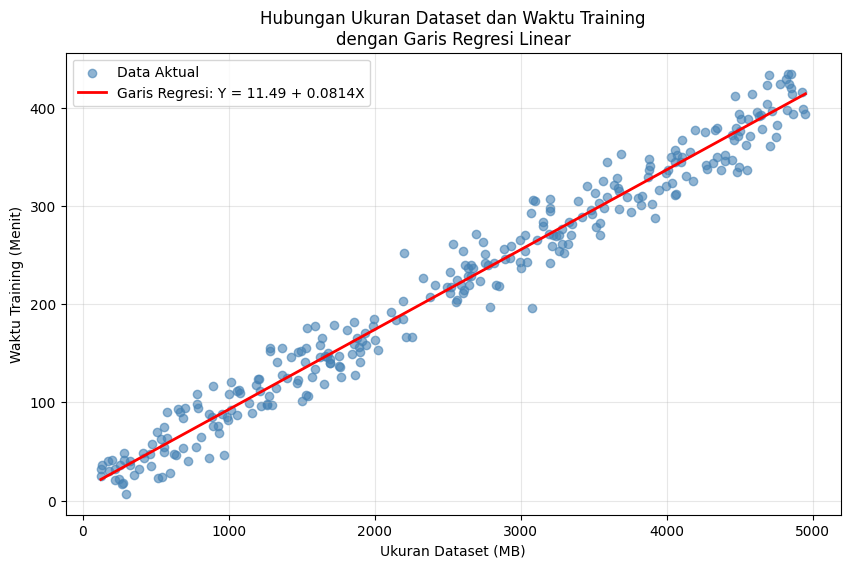

In [27]:
# Visualisasi garis regresi linear
plt.figure(figsize=(10, 6))

# Scatter plot data aktual
plt.scatter(
    df['training_data_size_mb'],
    df['training_time_minutes'],
    color='steelblue',
    alpha=0.6,
    label='Data Aktual'
)

# Garis regresi (diurutkan berdasarkan X agar garis terlihat lurus)
X_sorted = np.sort(df['training_data_size_mb'].values).reshape(-1, 1)
y_pred_sorted = model.predict(X_sorted)

plt.plot(
    X_sorted,
    y_pred_sorted,
    color='red',
    linewidth=2,
    label=f'Garis Regresi: Y = {intercept:.2f} + {koefisien:.4f}X'
)

plt.xlabel('Ukuran Dataset (MB)')
plt.ylabel('Waktu Training (Menit)')
plt.title('Hubungan Ukuran Dataset dan Waktu Training\ndengan Garis Regresi Linear')
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

---
## Langkah 11 — Contoh Prediksi Data Baru

Model yang telah dilatih dapat digunakan untuk memprediksi waktu training pada data baru yang belum pernah dilihat sebelumnya.

Di bawah ini, kita akan mencoba memprediksi waktu training untuk dataset berukuran **1500 MB**.

In [28]:
# Contoh prediksi untuk dataset baru
ukuran_baru_mb = 1500

data_baru = pd.DataFrame({
    'training_data_size_mb': [ukuran_baru_mb]
})

hasil_prediksi = model.predict(data_baru)
prediksi_menit = hasil_prediksi[0]

# Konversi ke jam dan menit
jam = int(prediksi_menit // 60)
sisa_menit = prediksi_menit % 60

print(f"=== Prediksi Waktu Training untuk Dataset Baru ===")
print(f"Ukuran dataset input  : {ukuran_baru_mb} MB")
print(f"Prediksi waktu training: {prediksi_menit:.2f} menit")

if jam > 0:
    print(f"Dalam satuan jam/menit : {jam} jam {sisa_menit:.2f} menit")
else:
    print(f"Dalam satuan menit     : {sisa_menit:.2f} menit")

=== Prediksi Waktu Training untuk Dataset Baru ===
Ukuran dataset input  : 1500 MB
Prediksi waktu training: 133.53 menit
Dalam satuan jam/menit : 2 jam 13.53 menit


In [29]:
# Periksa apakah input berada di luar rentang data training
x_min = df['training_data_size_mb'].min()
x_max = df['training_data_size_mb'].max()

print(f"Rentang data training : {x_min:.2f} MB — {x_max:.2f} MB")
print(f"Nilai input           : {ukuran_baru_mb} MB")

if ukuran_baru_mb < x_min or ukuran_baru_mb > x_max:
    print("\n⚠️  PERINGATAN: Nilai input berada DI LUAR rentang data training!")
    print("   Prediksi ini merupakan EKSTRAPOLASI dan mungkin kurang akurat.")
    print("   Model belum pernah melihat data di luar rentang ini saat pelatihan.")
else:
    print("\n✅ Nilai input berada di DALAM rentang data training.")
    print("   Prediksi ini merupakan INTERPOLASI dan relatif lebih dapat dipercaya.")

Rentang data training : 124.80 MB — 4951.26 MB
Nilai input           : 1500 MB

✅ Nilai input berada di DALAM rentang data training.
   Prediksi ini merupakan INTERPOLASI dan relatif lebih dapat dipercaya.


---
## Langkah 12 — Kesimpulan Analisis

### Kesimpulan

Berdasarkan seluruh proses analisis yang telah dilakukan, dapat diambil beberapa kesimpulan sebagai berikut:

---

**1. Hubungan antara Ukuran Dataset dan Waktu Training**

Berdasarkan hasil analisis korelasi Pearson dan visualisasi pairplot, terdapat **hubungan yang signifikan** antara ukuran dataset pelatihan (`training_data_size_mb`) dan waktu yang dibutuhkan untuk melatih model (`training_time_minutes`). Nilai korelasi yang tinggi mengindikasikan bahwa kedua variabel memiliki keterkaitan yang erat.

---

**2. Arah Hubungan Kedua Variabel**

Hubungan antara kedua variabel bersifat **positif**, artinya semakin besar ukuran dataset, maka semakin lama waktu yang dibutuhkan untuk melatih model. Hal ini sesuai dengan logika komputasi, karena dataset yang lebih besar memerlukan lebih banyak iterasi dan kalkulasi dalam proses pelatihan.

---

**3. Performa Model Regresi Linear**

Model Regresi Linear Sederhana yang telah dilatih menghasilkan metrik evaluasi sebagai berikut:
- **R²** yang tinggi menunjukkan bahwa model mampu menjelaskan sebagian besar variansi waktu training berdasarkan ukuran dataset
- **MAE** dan **RMSE** menunjukkan rata-rata kesalahan prediksi model dalam satuan menit
- **MSE** yang merupakan rata-rata kuadrat kesalahan sensitif terhadap outlier

Secara keseluruhan, model menunjukkan performa yang **cukup baik** untuk data yang digunakan dalam praktikum ini.

---

**4. Kemampuan Model untuk Memperkirakan Waktu Training**

Model Regresi Linear Sederhana yang telah dibuat **dapat digunakan** untuk memperkirakan waktu training berdasarkan ukuran dataset. Model ini paling andal untuk memprediksi dalam rentang data yang sudah diketahui (interpolasi). Prediksi di luar rentang data (ekstrapolasi) memiliki tingkat ketidakpastian yang lebih tinggi.

---

**5. Keterbatasan Model**

Model ini memiliki beberapa keterbatasan yang perlu diperhatikan:

- **Hanya satu variabel prediktor:** Model menggunakan satu variabel saja (ukuran dataset), padahal waktu training dipengaruhi banyak faktor lain seperti jenis algoritma, arsitektur model, spesifikasi hardware (CPU/GPU), dan kompleksitas data.
- **Asumsi hubungan linear:** Regresi Linear mengasumsikan hubungan antara X dan y bersifat linear, padahal dalam praktiknya hubungan tersebut bisa lebih kompleks.
- **Keterbatasan dataset:** Hasil prediksi berlaku berdasarkan pola data yang digunakan dalam penelitian ini dan **belum tentu mewakili semua jenis algoritma maupun spesifikasi komputer** yang berbeda.
- **Ekstrapolasi berisiko:** Prediksi untuk ukuran dataset yang jauh di luar rentang data training kurang dapat diandalkan.